# mid-term project

https://www.kaggle.com/datasets/youssefaboelwafa/hotel-booking-cancellation-prediction

## data preparation

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
# !curl -L -o data/hotel-booking-cancellation-prediction.zip https://www.kaggle.com/api/v1/datasets/download/youssefaboelwafa/hotel-booking-cancellation-prediction
# !unzip -o data/hotel-booking-cancellation-prediction.zip -d data/
df_orig = pd.read_csv('data/booking.csv')

In [3]:
df = df_orig.copy()

In [4]:
df.shape

(36285, 17)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 36285 entries, 0 to 36284
Data columns (total 17 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Booking_ID                36285 non-null  str    
 1   number of adults          36285 non-null  int64  
 2   number of children        36285 non-null  int64  
 3   number of weekend nights  36285 non-null  int64  
 4   number of week nights     36285 non-null  int64  
 5   type of meal              36285 non-null  str    
 6   car parking space         36285 non-null  int64  
 7   room type                 36285 non-null  str    
 8   lead time                 36285 non-null  int64  
 9   market segment type       36285 non-null  str    
 10  repeated                  36285 non-null  int64  
 11  P-C                       36285 non-null  int64  
 12  P-not-C                   36285 non-null  int64  
 13  average price             36285 non-null  float64
 14  special requests 

In [6]:
df.describe().round(3)

,number of adults,number of children,number of weekend nights,number of week nights,car parking space,lead time,repeated,P-C,P-not-C,average price,special requests
count,36285.000,36285.000,36285.000,36285.000,36285.000,36285.000,36285.000,36285.000,36285.000,36285.000,36285.000
mean,1.845,0.105,0.811,2.205,0.031,85.240,0.026,0.023,0.153,103.422,0.620
std,0.519,0.403,0.871,1.411,0.173,85.939,0.158,0.368,1.754,35.086,0.786
min,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
25%,2.000,0.000,0.000,1.000,0.000,17.000,0.000,0.000,0.000,80.300,0.000
50%,2.000,0.000,1.000,2.000,0.000,57.000,0.000,0.000,0.000,99.450,0.000
75%,2.000,0.000,2.000,3.000,0.000,126.000,0.000,0.000,0.000,120.000,1.000
max,4.000,10.000,7.000,17.000,1.000,443.000,1.000,13.000,58.000,540.000,5.000


In [7]:
df.head().T

,0,1,2,3,4
Booking_ID,INN00001,INN00002,INN00003,INN00004,INN00005
number of adults,1,1,2,1,1
number of children,1,0,1,0,0
number of weekend nights,2,1,1,0,1
number of week nights,5,3,3,2,2
type of meal,Meal Plan 1,Not Selected,Meal Plan 1,Meal Plan 1,Not Selected
car parking space,0,0,0,0,0
room type,Room_Type 1,Room_Type 1,Room_Type 1,Room_Type 1,Room_Type 1
lead time,224,5,1,211,48
market segment type,Offline,Online,Online,Online,Online


### EDA


In [8]:
df.isnull().sum().sort_values(ascending=False)

Booking_ID                  0
number of adults            0
number of children          0
number of weekend nights    0
number of week nights       0
type of meal                0
car parking space           0
room type                   0
lead time                   0
market segment type         0
repeated                    0
P-C                         0
P-not-C                     0
average price               0
special requests            0
date of reservation         0
booking status              0
dtype: int64

In [9]:
df.columns = df.columns.str.lower().str.replace(' ', '_').str.replace('-', '_')

categorical_columns = df.select_dtypes(include=['object', 'category', 'str']).columns.tolist()

for c in categorical_columns:
    df[c] = df[c].str.lower().str.replace(' ', '_')

df['is_canceled'] = (df.booking_status == 'canceled').astype(int)
df = df.drop(columns="booking_status")

In [10]:
df.head().T

,0,1,2,3,4
booking_id,inn00001,inn00002,inn00003,inn00004,inn00005
number_of_adults,1,1,2,1,1
number_of_children,1,0,1,0,0
number_of_weekend_nights,2,1,1,0,1
number_of_week_nights,5,3,3,2,2
type_of_meal,meal_plan_1,not_selected,meal_plan_1,meal_plan_1,not_selected
car_parking_space,0,0,0,0,0
room_type,room_type_1,room_type_1,room_type_1,room_type_1,room_type_1
lead_time,224,5,1,211,48
market_segment_type,offline,online,online,online,online


check invalid date_of_reservation,
and replace 2018-2-29 with 2018-02-28

In [11]:
temp_dates = pd.to_datetime(df['date_of_reservation'], errors='coerce')
invalid_rows = df[temp_dates.isna()]

print(f"length invalid rows : {len(invalid_rows)}")
max_date = invalid_rows['date_of_reservation'].max()
min_date = invalid_rows['date_of_reservation'].min()
print(f'range date_of_reservation : {min_date} to {max_date}')

df.loc[df['date_of_reservation'] == '2018-2-29', 'date_of_reservation'] = '2/28/2018'

length invalid rows : 37
range date_of_reservation : 2018-2-29 to 2018-2-29


In [12]:
df['date_of_reservation'] = pd.to_datetime(df['date_of_reservation'])
df['res_month'] = df['date_of_reservation'].dt.month.astype('str')
df['res_dow'] = df['date_of_reservation'].dt.day_of_week.astype('str')

check 0 guests,


In [13]:
ghost_bookings = df[(df['number_of_adults'] == 0) & (df['number_of_children'] == 0)]
ghost_bookings.value_counts().sum()

np.int64(0)

check 0 average price per room,

In [14]:
zero_price_bookings = df[df.average_price == 0]
zero_price_bookings.value_counts().sum()

segment_counts = zero_price_bookings['market_segment_type'].value_counts()
print("0 average price bookings by market segment type:")
print(segment_counts)

0 average price bookings by market segment type:
market_segment_type
complementary    354
online           191
Name: count, dtype: int64


In [15]:
df['total_guests'] = df['number_of_adults'] + df['number_of_children']
df['total_nights'] = df['number_of_weekend_nights'] + df['number_of_week_nights']

In [16]:
df.head().T

,0,1,2,3,4
booking_id,inn00001,inn00002,inn00003,inn00004,inn00005
number_of_adults,1,1,2,1,1
number_of_children,1,0,1,0,0
number_of_weekend_nights,2,1,1,0,1
number_of_week_nights,5,3,3,2,2
type_of_meal,meal_plan_1,not_selected,meal_plan_1,meal_plan_1,not_selected
car_parking_space,0,0,0,0,0
room_type,room_type_1,room_type_1,room_type_1,room_type_1,room_type_1
lead_time,224,5,1,211,48
market_segment_type,offline,online,online,online,online


In [17]:
df.describe().T.round(2)

,count,mean,min,25%,50%,75%,max,std
number_of_adults,36285.0,1.844839,0.0,2.0,2.0,2.0,4.0,0.518813
number_of_children,36285.0,0.10536,0.0,0.0,0.0,0.0,10.0,0.402704
number_of_weekend_nights,36285.0,0.810693,0.0,0.0,1.0,2.0,7.0,0.87059
number_of_week_nights,36285.0,2.204602,0.0,1.0,2.0,3.0,17.0,1.410946
car_parking_space,36285.0,0.030977,0.0,0.0,0.0,0.0,1.0,0.173258
lead_time,36285.0,85.239851,0.0,17.0,57.0,126.0,443.0,85.938796
repeated,36285.0,0.02563,0.0,0.0,0.0,0.0,1.0,0.158032
p_c,36285.0,0.023343,0.0,0.0,0.0,0.0,13.0,0.368281
p_not_c,36285.0,0.153369,0.0,0.0,0.0,0.0,58.0,1.753931
average_price,36285.0,103.421636,0.0,80.3,99.45,120.0,540.0,35.086469


In [18]:
cat_cols = ['type_of_meal', 'room_type', 'market_segment_type', 'res_month', 'res_dow']
num_cols = ['number_of_adults', 'number_of_children', 'number_of_weekend_nights',
            'number_of_week_nights', 'car_parking_space', 'lead_time', 'repeated',
            'p_c', 'p_not_c', 'average_price', 'special_requests']


np.int64(545)

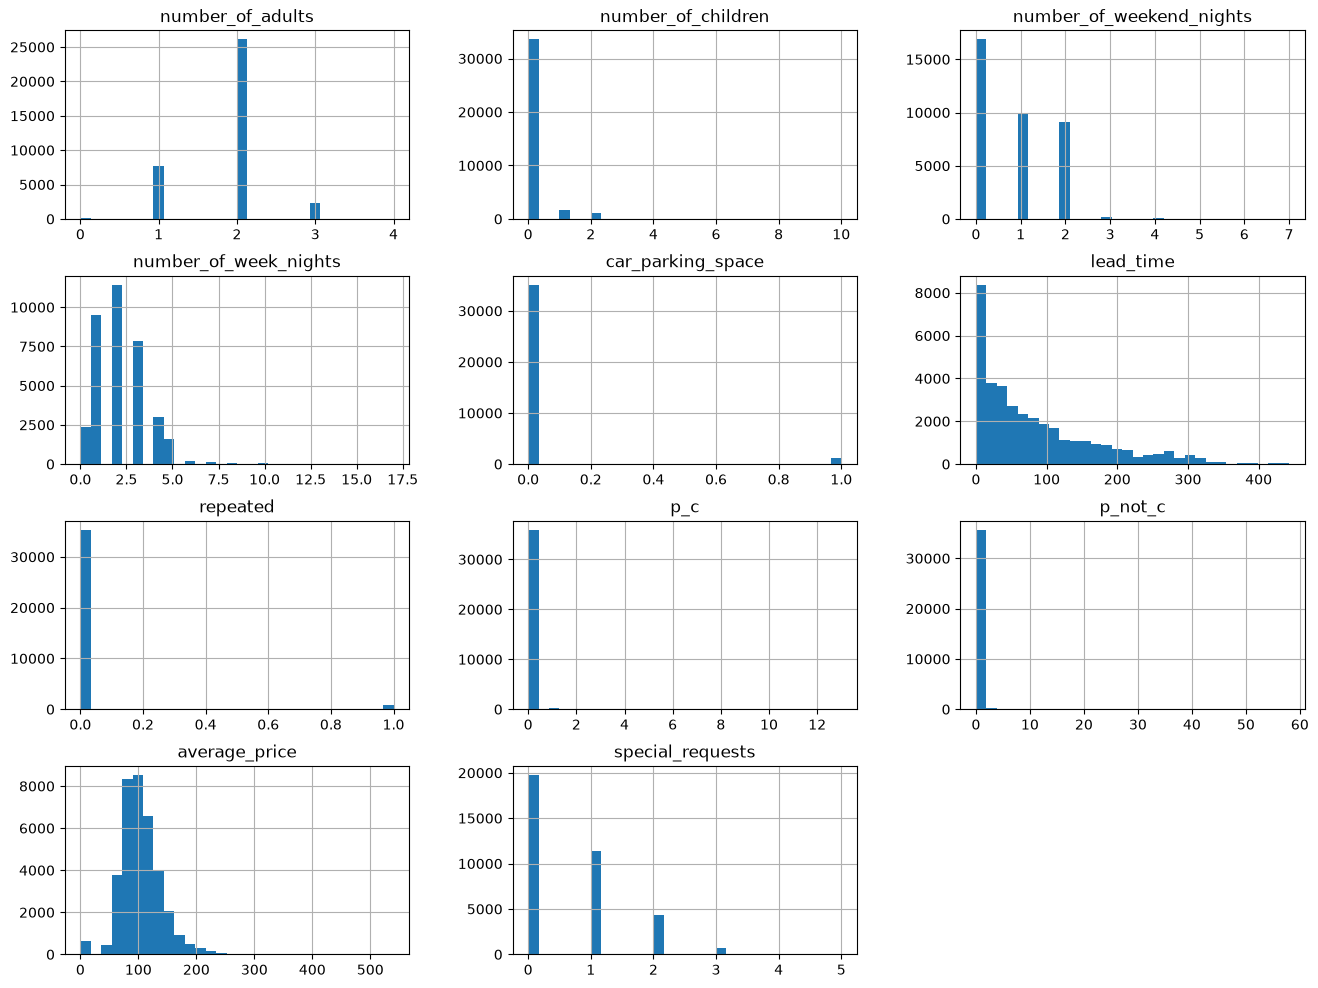

In [19]:

# Distribusi tiap fitur numerik
df[num_cols].hist(bins=30, figsize=(16, 12))

# Outlier
sns.boxplot(x=df['lead_time'])
sns.boxplot(x=df['average_price'])

# Distribusi kategori
sns.countplot(x='market_segment_type', data=df)

# Jumlah reservasi per bulan / hari
sns.countplot(x='res_month', data=df)

# Cek nilai janggal (harga 0, adults 0)
(df['average_price'] == 0).sum()

==============================================================================

In [20]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.metrics import roc_auc_score

In [21]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1, stratify=df['is_canceled'])
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1, stratify=df_full_train['is_canceled'])

In [22]:
len(df_train), len(df_val), len(df_test), len(df_full_train)

(21771, 7257, 7257, 29028)

In [23]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [24]:
y_train = df_train.is_canceled.values
y_val = df_val.is_canceled.values
y_test = df_test.is_canceled.values

In [25]:
del df_train['is_canceled']
del df_val['is_canceled']
del df_test['is_canceled']

In [26]:
print(len(y_train), len(y_val), len(y_test))

for name, y in [('train', y_train), ('val', y_val), ('test', y_test)]:
    print(name, y.mean().round(3))

21771 7257 7257
train 0.328
val 0.328
test 0.328


In [27]:
# 1. Distribusi target
global_cancelation_rate = df_full_train.is_canceled.mean()
global_cancelation_rate.round(3)

np.float64(0.328)

In [28]:
from IPython.display import display

In [29]:
for c in cat_cols :    
    # print(c)
    print(f"{c}   |   global cancelation = {global_cancelation_rate:.4f}")
    df_group = df_full_train.groupby(c).is_canceled.agg(['mean', 'count'])
    df_group['diff'] = df_group['mean'] - global_cancelation_rate
    df_group['risk'] = df_group['mean'] / global_cancelation_rate
    display(df_group.sort_values('risk', ascending=False))
    # display(df_group)
    df_group
    print()
    print()

type_of_meal   |   global cancelation = 0.3276


,mean,count,diff,risk
type_of_meal,,,,
meal_plan_2,0.458365,2642,0.130716,1.398950
meal_plan_3,0.333333,3,0.005684,1.017348
not_selected,0.331470,4115,0.003821,1.011662
meal_plan_1,0.311433,22268,-0.016216,0.950509




room_type   |   global cancelation = 0.3276


,mean,count,diff,risk
room_type,,,,
room_type_6,0.412533,766,0.084883,1.259068
room_type_3,0.400000,5,0.072351,1.220818
room_type_2,0.343693,547,0.016044,1.048966
room_type_4,0.337364,4879,0.009715,1.029651
room_type_1,0.323315,22492,-0.004334,0.986772
room_type_5,0.268519,216,-0.059131,0.819531
room_type_7,0.235772,123,-0.091877,0.719588




market_segment_type   |   global cancelation = 0.3276


,mean,count,diff,risk
market_segment_type,,,,
online,0.363426,18609,0.035777,1.109193
offline,0.302929,8398,-0.024720,0.924554
aviation,0.280000,100,-0.047649,0.854573
corporate,0.109657,1605,-0.217992,0.334679
complementary,0.000000,316,-0.327649,0.000000




res_month   |   global cancelation = 0.3276


,mean,count,diff,risk
res_month,,,,
7,0.454390,2346,0.126741,1.386820
6,0.406986,2548,0.079337,1.242139
8,0.378625,3069,0.050976,1.155580
4,0.367774,2197,0.040125,1.122464
5,0.361381,2056,0.033732,1.102952
10,0.358116,4183,0.030467,1.092987
9,0.330470,3725,0.002821,1.008609
3,0.295039,1915,-0.032610,0.900473
11,0.291876,2388,-0.035773,0.890819




res_dow   |   global cancelation = 0.3276


,mean,count,diff,risk
res_dow,,,,
6,0.374194,4960,0.046544,1.142056
2,0.327388,4093,-0.000261,0.999204
1,0.324539,3904,-0.003110,0.990507
5,0.322647,4367,-0.005002,0.984734
4,0.312582,3791,-0.015067,0.954016
3,0.311475,3599,-0.016174,0.950637
0,0.308994,4314,-0.018655,0.943064


In [30]:
# numerical correlation with target
df_full_train[num_cols].corrwith(df_full_train.is_canceled).sort_values(ascending=False)

lead_time                   0.439481
average_price               0.137427
number_of_week_nights       0.090510
number_of_adults            0.087355
number_of_weekend_nights    0.065825
number_of_children          0.030217
p_c                        -0.031653
p_not_c                    -0.060286
car_parking_space          -0.088882
repeated                   -0.107073
special_requests           -0.257494
dtype: float64

In [31]:
# numerical correlation with target
df_full_train.groupby('is_canceled')[num_cols].mean().T

is_canceled,0,1
number_of_adults,1.812061,1.908422
number_of_children,0.096480,0.122490
number_of_weekend_nights,0.770969,0.893176
number_of_week_nights,2.116719,2.389128
car_parking_space,0.042322,0.009252
lead_time,58.936978,139.465356
repeated,0.037147,0.001262
p_c,0.031306,0.006519
p_not_c,0.220987,0.001682
average_price,100.003310,110.276787


In [32]:
# mutual information
from sklearn.metrics import mutual_info_score

def mutual_info_cancelation_score(series):
    return mutual_info_score(series, df_full_train.is_canceled)

mi = df_full_train[cat_cols].apply(mutual_info_cancelation_score)
mi.sort_values(ascending=False)

res_month              0.022967
market_segment_type    0.013765
type_of_meal           0.003815
res_dow                0.001094
room_type              0.000645
dtype: float64

In [33]:
features = cat_cols + num_cols

In [34]:
# Lead time dalam bin (cek hubungan non-linear)
bins = pd.cut(df_full_train.lead_time, [-1, 7, 30, 90, 180, 365, 1000])
df_full_train.groupby(bins).is_canceled.agg(['mean', 'count'])


,mean,count
lead_time,,
"(-1, 7]",0.087181,4657
"(7, 30]",0.187843,5281
"(30, 90]",0.254752,8628
"(90, 180]",0.448901,6233
"(180, 365]",0.726190,4032
"(365, 1000]",0.959391,197


In [35]:
# Bulan vs tahun (apakah pola bulan konsisten antar tahun?)
df_full_train['year'] = df_full_train.date_of_reservation.dt.year
df_full_train.pivot_table(index='res_month', columns='year',
                          values='is_canceled', aggfunc=['mean', 'count'])


mean                          count                     
year      2015 2016      2017      2018  2015 2016    2017    2018
res_month                                                         
1          NaN  NaN       NaN  0.023428   NaN  NaN     NaN   811.0
10         0.0  NaN  0.164806  0.468973   1.0  NaN  1523.0  2659.0
11         NaN  NaN  0.046065  0.360471   NaN  NaN   521.0  1867.0
12         NaN  NaN  0.024194  0.182912   NaN  NaN   744.0  1662.0
2          NaN  NaN       NaN  0.262283   NaN  NaN     NaN  1384.0
3          NaN  NaN       NaN  0.295039   NaN  NaN     NaN  1915.0
4          NaN  NaN       NaN  0.367774   NaN  NaN     NaN  2197.0
5          NaN  NaN       NaN  0.361381   NaN  NaN     NaN  2056.0
6          NaN  NaN       NaN  0.406986   NaN  NaN     NaN  2548.0
7          NaN  NaN  0.678930  0.421593   NaN  NaN   299.0  2047.0
8          NaN  NaN  0.170135  0.454263   NaN  NaN   817.0  2252.0
9          NaN  1.0  0.111862  0.451923   NaN  1.0  1332.0  2392.0

In [36]:
# Harga 0 dan segmen
(df_full_train.average_price == 0).sum()
df_full_train[df_full_train.average_price == 0].market_segment_type.value_counts()


market_segment_type
complementary    288
online           151
Name: count, dtype: int64

In [37]:
df_full_train.groupby(df_full_train.p_not_c > 0).is_canceled.agg(['mean', 'count'])

,mean,count
p_not_c,,
False,0.334872,28387
True,0.007800,641


In [38]:
# Uji dugaan: apakah lead_time rata-rata beda antar bulan/tahun?
df_full_train.groupby(['year', 'res_month']).lead_time.agg(['mean', 'median', 'count'])

mean  median  count
year res_month                           
2015 10         224.000000   224.0      1
2016 9          346.000000   346.0      1
2017 10          67.866054    40.0   1523
     11          34.270633    32.0    521
     12          46.680108    22.0    744
     7          147.093645   108.0    299
     8           41.941248    11.0    817
     9           56.881381    32.0   1332
2018 1           33.704069    15.0    811
     10         125.484769    91.0   2659
     11          83.214783    49.0   1867
     12          88.096270    50.0   1662
     2           30.596821    16.0   1384
     3           47.558225    41.0   1915
     4           74.741466    65.0   2197
     5           85.146401    68.0   2056
     6          101.349294    79.0   2548
     7          112.142648   110.0   2047
     8          115.266874   121.0   2252
     9          118.461957    70.0   2392

In [39]:
# Dua baris 2015/2016
df_full_train[df_full_train.year < 2017]

,booking_id,number_of_adults,number_of_children,number_of_weekend_nights,number_of_week_nights,type_of_meal,car_parking_space,room_type,lead_time,market_segment_type,...,p_not_c,average_price,special_requests,date_of_reservation,is_canceled,res_month,res_dow,total_guests,total_nights,year
5,inn00006,1,0,0,2,meal_plan_2,0,room_type_1,346,offline,...,0,100.0,1,2016-09-13,1,9,1,1,2,2016
0,inn00001,1,1,2,5,meal_plan_1,0,room_type_1,224,offline,...,0,88.0,0,2015-10-02,0,10,4,2,7,2015


In [40]:
# Harga 0 per segmen
df_full_train[df_full_train.average_price == 0] \
    .groupby('market_segment_type').is_canceled.agg(['mean', 'count'])



,mean,count
market_segment_type,,
complementary,0.00000,288
online,0.02649,151


In [41]:
# Riwayat cancel
df_full_train.groupby(df_full_train.p_c > 0).is_canceled.agg(['mean', 'count'])

,mean,count
p_c,,
False,0.330308,28758
True,0.044444,270


### Model training

In [42]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb
from sklearn.model_selection import KFold

#### model logistic regression

In [43]:
dv = DictVectorizer(sparse=False)

train_dict = df_train[cat_cols + num_cols].to_dict(orient='records')
X_train = dv.fit_transform(train_dict)

In [ ]:
model = LogisticRegression(solver='liblinear')
model.fit(X_train, y_train)

,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some pen

In [45]:
val_dict = df_val[cat_cols + num_cols].to_dict(orient='records')
X_val = dv.transform(val_dict)

In [46]:
y_pred = model.predict_proba(X_val)[:, 1]

cancel_decision = (y_pred >= 0.5)
(y_val == cancel_decision).mean()

np.float64(0.8102521703183133)

In [47]:
roc_auc_score(y_val, y_pred)

0.8732966037139998

C = 1

In [ ]:
for C in [0.01, 0.1, 1, 10]:
    lr = LogisticRegression(C=C, solver='liblinear')
    lr.fit(X_train, y_train)
    print(C, round(roc_auc_score(y_val, lr.predict_proba(X_val)[:, 1]), 4))

0.01 0.8691
0.1 0.8732
1 0.8733
10 0.8732


#### model random forest & tuning parameter

In [49]:
rf = RandomForestClassifier(n_estimators=100, random_state=1, n_jobs=-1)
rf.fit(X_train, y_train)

y_pred_rf = rf.predict_proba(X_val)[:, 1]
roc_auc_score(y_val, y_pred_rf)

0.9498165961085864

In [50]:
for d in [5, 10, 15, 20, None]:
    rf = RandomForestClassifier(n_estimators=100, max_depth=d, random_state=1, n_jobs=-1)
    rf.fit(X_train, y_train)
    auc = roc_auc_score(y_val, rf.predict_proba(X_val)[:, 1])
    print(d, round(auc, 4))

5 0.877
10 0.9268
15 0.9464
20 0.9525
None 0.9498


max_depth = 20, min_samples_leaf = 1

In [51]:
for leaf in [1, 3, 5, 10, 20]:
    rf = RandomForestClassifier(n_estimators=100, max_depth=20, min_samples_leaf=leaf,
                                random_state=1, n_jobs=-1)
    rf.fit(X_train, y_train)
    auc = roc_auc_score(y_val, rf.predict_proba(X_val)[:, 1])
    print(leaf, round(auc, 4))

1 0.9525
3 0.9458
5 0.9425
10 0.9354
20 0.9266


In [52]:
for n in [50, 100, 200, 300]:
    rf = RandomForestClassifier(n_estimators=n, max_depth=20, min_samples_leaf=1,
                                random_state=1, n_jobs=-1)
    rf.fit(X_train, y_train)
    auc = roc_auc_score(y_val, rf.predict_proba(X_val)[:, 1])
    print(n, round(auc, 4))

50 0.951
100 0.9525
200 0.9528
300 0.9526


In [53]:
# rf_final = RandomForestClassifier(n_estimators=100, max_depth=20, min_samples_leaf=1, random_state=1, n_jobs=-1)

#### model xgboost and tuning parameter

In [54]:
xgb_model = xgb.XGBClassifier(n_estimators=100, random_state=1)
xgb_model.fit(X_train, y_train)

y_pred_xgb = xgb_model.predict_proba(X_val)[:, 1]
roc_auc_score(y_val, y_pred_xgb)

0.9517553990764904

Xgboost without res_dow, res_month

In [55]:
cat_cols_B = ['type_of_meal', 'room_type', 'market_segment_type']

dv_B = DictVectorizer(sparse=False)
X_train_B = dv_B.fit_transform(df_train[cat_cols_B + num_cols].to_dict(orient='records'))
X_val_B = dv_B.transform(df_val[cat_cols_B + num_cols].to_dict(orient='records'))

xgb_B = xgb.XGBClassifier(n_estimators=100, random_state=1)
xgb_B.fit(X_train_B, y_train)

roc_auc_score(y_val, xgb_B.predict_proba(X_val_B)[:, 1])

0.9396216875640284

Xgboost without res_dow

In [56]:
cat_cols_C = ['type_of_meal', 'room_type', 'market_segment_type', 'res_month']

dv_C = DictVectorizer(sparse=False)
X_train_C = dv_C.fit_transform(df_train[cat_cols_C + num_cols].to_dict(orient='records'))
X_val_C = dv_C.transform(df_val[cat_cols_C + num_cols].to_dict(orient='records'))

xgb_C = xgb.XGBClassifier(n_estimators=100, random_state=1)
xgb_C.fit(X_train_C, y_train)

roc_auc_score(y_val, xgb_C.predict_proba(X_val_C)[:, 1])

0.9499123532980035

In [57]:
X_train = X_train_C
X_val = X_val_C

for d in [3, 5, 8, 10, 12, 15]:
    m = xgb.XGBClassifier(n_estimators=100, max_depth=d, random_state=1)
    m.fit(X_train, y_train)
    auc = roc_auc_score(y_val, m.predict_proba(X_val)[:, 1])
    print(d, round(auc, 4))

3 0.9308
5 0.9477
8 0.953
10 0.9543
12 0.9547
15 0.9538


In [58]:
for lr in [0.05, 0.1, 0.2, 0.3, 0.5]:
    m = xgb.XGBClassifier(n_estimators=100, max_depth=10, learning_rate=lr, random_state=1)
    m.fit(X_train, y_train)
    auc = roc_auc_score(y_val, m.predict_proba(X_val)[:, 1])
    print(lr, round(auc, 4))

0.05 0.9496
0.1 0.9524
0.2 0.9543
0.3 0.9543
0.5 0.9529


max_depth = 10, lr=0.3, mcw=1,

In [59]:
for mcw in [1, 3, 5, 10, 20]:
    m = xgb.XGBClassifier(n_estimators=100, max_depth=10, learning_rate=0.2,
                          min_child_weight=mcw, random_state=1)
    m.fit(X_train, y_train)
    auc = roc_auc_score(y_val, m.predict_proba(X_val)[:, 1])
    print(mcw, round(auc, 4))

1 0.9543
3 0.9535
5 0.9518
10 0.9493
20 0.9451


In [60]:
# xgb_final = xgb.XGBClassifier(n_estimators=100, max_depth=10, learning_rate=0.2, min_child_weight=1, random_state=1)

try folding

In [61]:
cat_cols_final = ['type_of_meal', 'room_type', 'market_segment_type', 'res_month']

features_final = cat_cols_final + num_cols   # set C: tanpa res_dow

def train(df_train, y_train, model):
    dicts = df_train[features_final].to_dict(orient='records')
    dv = DictVectorizer(sparse=False)
    X = dv.fit_transform(dicts)
    model.fit(X, y_train)
    return dv, model

def predict(df, dv, model):
    dicts = df[features_final].to_dict(orient='records')
    X = dv.transform(dicts)
    return model.predict_proba(X)[:, 1]

## Cross-validation

In [62]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)

def cv_score(make_model):
    scores = []
    for i, (train_idx, val_idx) in enumerate(kfold.split(df_full_train), start=1):
        df_tr = df_full_train.iloc[train_idx]
        df_va = df_full_train.iloc[val_idx]

        y_tr = df_tr.is_canceled.values
        y_va = df_va.is_canceled.values

        dv, model = train(df_tr, y_tr, make_model())
        y_pred = predict(df_va, dv, model)

        scores.append(roc_auc_score(y_va, y_pred))
        print(f'  fold {i}/5: AUC = {scores[-1]:.4f}',f'Mean: {np.mean(scores):.4f}, Std: {np.std(scores):.4f}')

    return np.mean(scores), np.std(scores)

#### Random Forest

In [63]:
# Random Forest
cv_score(lambda: RandomForestClassifier(
    n_estimators=100, max_depth=20, random_state=1, n_jobs=-1))

  fold 1/5: AUC = 0.9512 Mean: 0.9512, Std: 0.0000
  fold 2/5: AUC = 0.9512 Mean: 0.9512, Std: 0.0000
  fold 3/5: AUC = 0.9481 Mean: 0.9502, Std: 0.0015
  fold 4/5: AUC = 0.9526 Mean: 0.9508, Std: 0.0016
  fold 5/5: AUC = 0.9496 Mean: 0.9505, Std: 0.0015


(np.float64(0.9505248600320154), np.float64(0.0015489331663785795))

tuning random forest with cross-validation

In [64]:
for d in [10, 15, 20, 25]:
    print(f'max_depth = {d}')
    mean, std = cv_score(lambda: RandomForestClassifier(
        n_estimators=100, max_depth=d, random_state=1, n_jobs=-1))
    print(f'==> max_depth={d} | mean: {mean:.4f}, std: {std:.4f}\n')

max_depth = 10
  fold 1/5: AUC = 0.9240 Mean: 0.9240, Std: 0.0000
  fold 2/5: AUC = 0.9249 Mean: 0.9244, Std: 0.0004
  fold 3/5: AUC = 0.9225 Mean: 0.9238, Std: 0.0010
  fold 4/5: AUC = 0.9240 Mean: 0.9238, Std: 0.0009
  fold 5/5: AUC = 0.9225 Mean: 0.9236, Std: 0.0009
==> max_depth=10 | mean: 0.9236, std: 0.0009

max_depth = 15
  fold 1/5: AUC = 0.9456 Mean: 0.9456, Std: 0.0000
  fold 2/5: AUC = 0.9456 Mean: 0.9456, Std: 0.0000
  fold 3/5: AUC = 0.9415 Mean: 0.9442, Std: 0.0019
  fold 4/5: AUC = 0.9472 Mean: 0.9450, Std: 0.0021
  fold 5/5: AUC = 0.9430 Mean: 0.9446, Std: 0.0021
==> max_depth=15 | mean: 0.9446, std: 0.0021

max_depth = 20
  fold 1/5: AUC = 0.9512 Mean: 0.9512, Std: 0.0000
  fold 2/5: AUC = 0.9512 Mean: 0.9512, Std: 0.0000
  fold 3/5: AUC = 0.9481 Mean: 0.9502, Std: 0.0015
  fold 4/5: AUC = 0.9526 Mean: 0.9508, Std: 0.0016
  fold 5/5: AUC = 0.9496 Mean: 0.9505, Std: 0.0015
==> max_depth=20 | mean: 0.9505, std: 0.0015

max_depth = 25
  fold 1/5: AUC = 0.9518 Mean: 0.9518

In [65]:
for leaf in [1, 3, 5]:
    print(f'min_samples_leaf = {leaf}')
    mean, std = cv_score(lambda: RandomForestClassifier(
        n_estimators=100, max_depth=20, min_samples_leaf=leaf, random_state=1, n_jobs=-1))
    print(f'==> min_samples_leaf={leaf} | mean: {mean:.4f}, std: {std:.4f}\n')

min_samples_leaf = 1
  fold 1/5: AUC = 0.9512 Mean: 0.9512, Std: 0.0000
  fold 2/5: AUC = 0.9512 Mean: 0.9512, Std: 0.0000
  fold 3/5: AUC = 0.9481 Mean: 0.9502, Std: 0.0015
  fold 4/5: AUC = 0.9526 Mean: 0.9508, Std: 0.0016
  fold 5/5: AUC = 0.9496 Mean: 0.9505, Std: 0.0015
==> min_samples_leaf=1 | mean: 0.9505, std: 0.0015

min_samples_leaf = 3
  fold 1/5: AUC = 0.9444 Mean: 0.9444, Std: 0.0000
  fold 2/5: AUC = 0.9469 Mean: 0.9457, Std: 0.0012
  fold 3/5: AUC = 0.9425 Mean: 0.9446, Std: 0.0018
  fold 4/5: AUC = 0.9471 Mean: 0.9452, Std: 0.0019
  fold 5/5: AUC = 0.9435 Mean: 0.9449, Std: 0.0018
==> min_samples_leaf=3 | mean: 0.9449, std: 0.0018

min_samples_leaf = 5
  fold 1/5: AUC = 0.9403 Mean: 0.9403, Std: 0.0000
  fold 2/5: AUC = 0.9424 Mean: 0.9413, Std: 0.0010
  fold 3/5: AUC = 0.9378 Mean: 0.9401, Std: 0.0019
  fold 4/5: AUC = 0.9422 Mean: 0.9407, Std: 0.0019
  fold 5/5: AUC = 0.9392 Mean: 0.9404, Std: 0.0018
==> min_samples_leaf=5 | mean: 0.9404, std: 0.0018



In [66]:
for n in [50, 100, 200]:
    print(f'n_estimators = {n}')
    mean, std = cv_score(lambda: RandomForestClassifier(
        n_estimators=n, max_depth=20, min_samples_leaf=1, random_state=1, n_jobs=-1))
    print(f'==> n_estimators={n} | mean: {mean:.4f}, std: {std:.4f}\n')

n_estimators = 50
  fold 1/5: AUC = 0.9501 Mean: 0.9501, Std: 0.0000
  fold 2/5: AUC = 0.9507 Mean: 0.9504, Std: 0.0003
  fold 3/5: AUC = 0.9469 Mean: 0.9492, Std: 0.0017
  fold 4/5: AUC = 0.9514 Mean: 0.9498, Std: 0.0017
  fold 5/5: AUC = 0.9484 Mean: 0.9495, Std: 0.0016
==> n_estimators=50 | mean: 0.9495, std: 0.0016

n_estimators = 100
  fold 1/5: AUC = 0.9512 Mean: 0.9512, Std: 0.0000
  fold 2/5: AUC = 0.9512 Mean: 0.9512, Std: 0.0000
  fold 3/5: AUC = 0.9481 Mean: 0.9502, Std: 0.0015
  fold 4/5: AUC = 0.9526 Mean: 0.9508, Std: 0.0016
  fold 5/5: AUC = 0.9496 Mean: 0.9505, Std: 0.0015
==> n_estimators=100 | mean: 0.9505, std: 0.0015

n_estimators = 200
  fold 1/5: AUC = 0.9522 Mean: 0.9522, Std: 0.0000
  fold 2/5: AUC = 0.9521 Mean: 0.9521, Std: 0.0000
  fold 3/5: AUC = 0.9487 Mean: 0.9510, Std: 0.0016
  fold 4/5: AUC = 0.9532 Mean: 0.9515, Std: 0.0017
  fold 5/5: AUC = 0.9504 Mean: 0.9513, Std: 0.0016
==> n_estimators=200 | mean: 0.9513, std: 0.0016



In [67]:
# final tuning with kfold(cross-validation)

# RandomForestClassifier(n_estimators=100, max_depth=20, min_samples_leaf=1, random_state=1, n_jobs=-1)

### xgboost tuning cross-validation

In [68]:
for d in [5, 8, 10, 12, 15]:
    print(f'max_depth = {d}')
    mean, std = cv_score(lambda: xgb.XGBClassifier(
        n_estimators=100, max_depth=d, learning_rate=0.2,
        min_child_weight=1, random_state=1))
    print(f'==> max_depth={d} | mean: {mean:.4f}, std: {std:.4f}\n')

max_depth = 5
  fold 1/5: AUC = 0.9422 Mean: 0.9422, Std: 0.0000
  fold 2/5: AUC = 0.9423 Mean: 0.9422, Std: 0.0000
  fold 3/5: AUC = 0.9397 Mean: 0.9414, Std: 0.0012
  fold 4/5: AUC = 0.9466 Mean: 0.9427, Std: 0.0025
  fold 5/5: AUC = 0.9406 Mean: 0.9423, Std: 0.0024
==> max_depth=5 | mean: 0.9423, std: 0.0024

max_depth = 8
  fold 1/5: AUC = 0.9523 Mean: 0.9523, Std: 0.0000
  fold 2/5: AUC = 0.9503 Mean: 0.9513, Std: 0.0010
  fold 3/5: AUC = 0.9490 Mean: 0.9505, Std: 0.0014
  fold 4/5: AUC = 0.9541 Mean: 0.9514, Std: 0.0019
  fold 5/5: AUC = 0.9481 Mean: 0.9508, Std: 0.0022
==> max_depth=8 | mean: 0.9508, std: 0.0022

max_depth = 10
  fold 1/5: AUC = 0.9536 Mean: 0.9536, Std: 0.0000
  fold 2/5: AUC = 0.9511 Mean: 0.9524, Std: 0.0013
  fold 3/5: AUC = 0.9501 Mean: 0.9516, Std: 0.0015
  fold 4/5: AUC = 0.9567 Mean: 0.9529, Std: 0.0025
  fold 5/5: AUC = 0.9514 Mean: 0.9526, Std: 0.0024
==> max_depth=10 | mean: 0.9526, std: 0.0024

max_depth = 12
  fold 1/5: AUC = 0.9539 Mean: 0.9539, St

In [69]:
for lr in [0.1, 0.2, 0.3]:
    print(f'learning_rate = {lr}')
    mean, std = cv_score(lambda: xgb.XGBClassifier(
        n_estimators=100, max_depth=10, learning_rate=lr,
        min_child_weight=1, random_state=1))
    print(f'==> learning_rate={lr} | mean: {mean:.4f}, std: {std:.4f}\n')

learning_rate = 0.1
  fold 1/5: AUC = 0.9515 Mean: 0.9515, Std: 0.0000
  fold 2/5: AUC = 0.9503 Mean: 0.9509, Std: 0.0006
  fold 3/5: AUC = 0.9484 Mean: 0.9501, Std: 0.0013
  fold 4/5: AUC = 0.9545 Mean: 0.9512, Std: 0.0022
  fold 5/5: AUC = 0.9490 Mean: 0.9508, Std: 0.0022
==> learning_rate=0.1 | mean: 0.9508, std: 0.0022

learning_rate = 0.2
  fold 1/5: AUC = 0.9536 Mean: 0.9536, Std: 0.0000
  fold 2/5: AUC = 0.9511 Mean: 0.9524, Std: 0.0013
  fold 3/5: AUC = 0.9501 Mean: 0.9516, Std: 0.0015
  fold 4/5: AUC = 0.9567 Mean: 0.9529, Std: 0.0025
  fold 5/5: AUC = 0.9514 Mean: 0.9526, Std: 0.0024
==> learning_rate=0.2 | mean: 0.9526, std: 0.0024

learning_rate = 0.3
  fold 1/5: AUC = 0.9526 Mean: 0.9526, Std: 0.0000
  fold 2/5: AUC = 0.9501 Mean: 0.9513, Std: 0.0012
  fold 3/5: AUC = 0.9494 Mean: 0.9507, Std: 0.0014
  fold 4/5: AUC = 0.9559 Mean: 0.9520, Std: 0.0025
  fold 5/5: AUC = 0.9507 Mean: 0.9517, Std: 0.0023
==> learning_rate=0.3 | mean: 0.9517, std: 0.0023



In [70]:
for mcw in [1, 3, 5]:
    print(f'min_child_weight = {mcw}')
    mean, std = cv_score(lambda: xgb.XGBClassifier(
        n_estimators=100, max_depth=10, learning_rate=0.2,
        min_child_weight=mcw, random_state=1))
    print(f'==> min_child_weight={mcw} | mean: {mean:.4f}, std: {std:.4f}\n')
    

min_child_weight = 1
  fold 1/5: AUC = 0.9536 Mean: 0.9536, Std: 0.0000
  fold 2/5: AUC = 0.9511 Mean: 0.9524, Std: 0.0013
  fold 3/5: AUC = 0.9501 Mean: 0.9516, Std: 0.0015
  fold 4/5: AUC = 0.9567 Mean: 0.9529, Std: 0.0025
  fold 5/5: AUC = 0.9514 Mean: 0.9526, Std: 0.0024
==> min_child_weight=1 | mean: 0.9526, std: 0.0024

min_child_weight = 3
  fold 1/5: AUC = 0.9514 Mean: 0.9514, Std: 0.0000
  fold 2/5: AUC = 0.9507 Mean: 0.9510, Std: 0.0003
  fold 3/5: AUC = 0.9486 Mean: 0.9502, Std: 0.0012
  fold 4/5: AUC = 0.9548 Mean: 0.9514, Std: 0.0022
  fold 5/5: AUC = 0.9499 Mean: 0.9511, Std: 0.0021
==> min_child_weight=3 | mean: 0.9511, std: 0.0021

min_child_weight = 5
  fold 1/5: AUC = 0.9518 Mean: 0.9518, Std: 0.0000
  fold 2/5: AUC = 0.9498 Mean: 0.9508, Std: 0.0010
  fold 3/5: AUC = 0.9480 Mean: 0.9499, Std: 0.0016
  fold 4/5: AUC = 0.9552 Mean: 0.9512, Std: 0.0027
  fold 5/5: AUC = 0.9484 Mean: 0.9506, Std: 0.0026
==> min_child_weight=5 | mean: 0.9506, std: 0.0026



In [71]:
# final tuning xgboost

# xgb.XGBClassifier(n_estimators=100, max_depth=10, learning_rate=0.2, min_child_weight=1, random_state=1)

#### logistic regression tuning 

In [ ]:
for C in [0.01, 0.1, 1, 10]:
    print(f'C = {C}')
    mean, std = cv_score(lambda: LogisticRegression(C=C, solver='liblinear'))
    print(f'==> C={C} | mean: {mean:.4f}, std: {std:.4f}\n')

C = 0.01
  fold 1/5: AUC = 0.8630 Mean: 0.8630, Std: 0.0000
  fold 2/5: AUC = 0.8682 Mean: 0.8656, Std: 0.0026
  fold 3/5: AUC = 0.8723 Mean: 0.8678, Std: 0.0038
  fold 4/5: AUC = 0.8659 Mean: 0.8673, Std: 0.0034
  fold 5/5: AUC = 0.8621 Mean: 0.8663, Std: 0.0037
==> C=0.01 | mean: 0.8663, std: 0.0037

C = 0.1
  fold 1/5: AUC = 0.8666 Mean: 0.8666, Std: 0.0000
  fold 2/5: AUC = 0.8700 Mean: 0.8683, Std: 0.0017
  fold 3/5: AUC = 0.8758 Mean: 0.8708, Std: 0.0038
  fold 4/5: AUC = 0.8727 Mean: 0.8713, Std: 0.0034
  fold 5/5: AUC = 0.8673 Mean: 0.8705, Std: 0.0034
==> C=0.1 | mean: 0.8705, std: 0.0034

C = 1
  fold 1/5: AUC = 0.8663 Mean: 0.8663, Std: 0.0000
  fold 2/5: AUC = 0.8697 Mean: 0.8680, Std: 0.0017
  fold 3/5: AUC = 0.8758 Mean: 0.8706, Std: 0.0039
  fold 4/5: AUC = 0.8734 Mean: 0.8713, Std: 0.0036
  fold 5/5: AUC = 0.8676 Mean: 0.8706, Std: 0.0035
==> C=1 | mean: 0.8706, std: 0.0035

C = 10
  fold 1/5: AUC = 0.8663 Mean: 0.8663, Std: 0.0000
  fold 2/5: AUC = 0.8696 Mean: 0.8679,

In [ ]:
# final tuning LogisticRegression 

# LogisticRegression(C=1, solver='liblinear')

final check

In [74]:
# cat_cols_final = ['type_of_meal', 'room_type', 'market_segment_type', 'res_month']

features_final = cat_cols_final + num_cols   # set C: tanpa res_dow

y_full_train = df_full_train.is_canceled.values

dv = DictVectorizer(sparse=False)
X_full_train = dv.fit_transform(df_full_train[features_final].to_dict(orient='records'))
X_test = dv.transform(df_test[features_final].to_dict(orient='records'))

xgb_final = xgb.XGBClassifier(n_estimators=100, max_depth=10, learning_rate=0.2,
                              min_child_weight=1, random_state=1)
xgb_final.fit(X_full_train, y_full_train)

y_pred_test = xgb_final.predict_proba(X_test)[:, 1]
roc_auc_score(y_test, y_pred_test)

0.954800968983462

## evaluation

oof = out of folding

In [75]:
y_full = df_full_train.is_canceled.values
oof = np.zeros(len(df_full_train))

for train_idx, val_idx in kfold.split(df_full_train):
    df_tr = df_full_train.iloc[train_idx]
    df_va = df_full_train.iloc[val_idx]

    dv_f, model_f = train(df_tr, df_tr.is_canceled.values,
                          xgb.XGBClassifier(n_estimators=100, max_depth=10,
                                            learning_rate=0.2, min_child_weight=1,
                                            random_state=1))
    oof[val_idx] = predict(df_va, dv_f, model_f)

print('OOF AUC:', round(roc_auc_score(y_full, oof), 4))

OOF AUC: 0.9525


In [76]:
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix

In [77]:
for t in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7]:
    pred = (oof >= t)
    print(f't={t} | precision: {precision_score(y_full, pred):.3f} '
          f'| recall: {recall_score(y_full, pred):.3f} '
          f'| f1: {f1_score(y_full, pred):.3f}')

t=0.2 | precision: 0.710 | recall: 0.913 | f1: 0.799
t=0.3 | precision: 0.775 | recall: 0.871 | f1: 0.820
t=0.4 | precision: 0.823 | recall: 0.836 | f1: 0.829
t=0.5 | precision: 0.859 | recall: 0.804 | f1: 0.830
t=0.6 | precision: 0.890 | recall: 0.761 | f1: 0.820
t=0.7 | precision: 0.923 | recall: 0.699 | f1: 0.796


### Threshold selection

Threshold chosen from out-of-fold predictions on the training data (5-fold, no test data
used). F1 is highest at 0.5 (0.830) and nearly flat between 0.4 and 0.5, so the default
0.5 is kept. A lower threshold (0.3-0.4) can be used if the hotel prefers higher recall,
at the cost of precision.

In [78]:
THRESHOLD = 0.5   # chosen from out-of-fold predictions on the training data

y_pred_class = (y_pred_test >= THRESHOLD)

print('AUC      :', round(roc_auc_score(y_test, y_pred_test), 4))
print('Precision:', round(precision_score(y_test, y_pred_class), 3))
print('Recall   :', round(recall_score(y_test, y_pred_class), 3))
print('F1       :', round(f1_score(y_test, y_pred_class), 3))
print(confusion_matrix(y_test, y_pred_class))

AUC      : 0.9548
Precision: 0.866
Recall   : 0.802
F1       : 0.833
[[4584  295]
 [ 471 1907]]


In [79]:
# for t in [0.3, 0.4, 0.5, 0.6, 0.7]:
#     pred = (y_pred_test >= t)
#     print(f't={t} | precision: {precision_score(y_test, pred):.3f} '
#           f'| recall: {recall_score(y_test, pred):.3f} '
#           f'| f1: {f1_score(y_test, pred):.3f}')

## Using the model

In [80]:
row = df_test.iloc[25]
booking = row[features_final].to_dict()

print(booking)
print('Actual is_canceled:', y_test[25])

{'type_of_meal': 'meal_plan_1', 'room_type': 'room_type_1', 'market_segment_type': 'offline', 'res_month': '10', 'number_of_adults': 3, 'number_of_children': 0, 'number_of_weekend_nights': 0, 'number_of_week_nights': 1, 'car_parking_space': 0, 'lead_time': 23, 'repeated': 0, 'p_c': 0, 'p_not_c': 0, 'average_price': 119.4, 'special_requests': 1}
Actual is_canceled: 0


In [81]:
# predik
X_one = dv.transform([booking])          # dibungkus list
prob = xgb_final.predict_proba(X_one)[0, 1]
print(f'Probability cancel: {prob:.3f}')
print('decision (threshold 0.5):', prob >= 0.5)

Probability cancel: 0.001
decision (threshold 0.5): False


In [82]:
# test new data
booking_baru = {
    'type_of_meal': 'meal_plan_2',
    'room_type': 'room_type_2',
    'market_segment_type': 'online',
    'res_month': '7',
    'number_of_adults': 2,
    'number_of_children': 0,
    'number_of_weekend_nights': 1,
    'number_of_week_nights': 2,
    'car_parking_space': 0,
    'lead_time': 10,
    'repeated': 0,
    'p_c': 0,
    'p_not_c': 0,
    'average_price': 2.0,
    'special_requests': 0,
}

X_new = dv.transform([booking_baru])
print(xgb_final.predict_proba(X_new)[0, 1])

0.004986581
